How well can a painting’s auction price be explained by its characteristics, without taking the auction house’s valuation into account? And to how much does the artist’s name alone affect this?

Target: log(price) in USD

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.model_selection import GroupKFold, KFold, TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder

from scraper.artdb import ArtDB, EPOCH

random_seed = 42
np.random.seed(random_seed)
pd.set_option("display.width", 160, "display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 100})

Preparing dataset: only USD, since 2010 (to minimize inflation), paintings, already sold

In [2]:
db = ArtDB("data/artdb")
sc = db.schema

def build_frame(db):
    L, S, A = np.asarray(db.lots), db.sales, db.artists
    s, a = L["sale"].astype(np.int64), L["artist"].astype(np.int64)
    df = pd.DataFrame({
        "price": L["price"].astype(float),
        "artist": a,
        "sale": s,
        "sale_date": pd.Timestamp(EPOCH) + pd.to_timedelta(L["day"].astype(np.int64), unit="D"),
        "h_mm": L["h_mm"].astype(float), "w_mm": L["w_mm"].astype(float),
        "year_created": L["year"].astype(float),
        "lot": L["lot"].astype(float),
    })
    for k, enum in [("category", "categories"), ("medium", "mediums"),
                    ("support", "supports"), ("attribution", "attributions")]:
        df[k] = np.array(sc[enum])[db.flag(k)]
    for k in ["sold", "withdrawn", "signed", "dated", "inscribed", "stamped", "circa", "round"]:
        df[k] = db.flag(k).astype(np.int8)
    df["currency"] = np.array(sc["currencies"])[S["currency"][s]]
    df["room"] = np.array(sc["rooms"])[S["room"][s]]
    df["evening_sale"] = (S["flags"][s] & 1).astype(np.int8)
    df["sale_size"] = S["n_listed"][s].astype(float)
    df["artist_born"] = A["born"][a].astype(float)
    df["artist_died"] = A["died"][a].astype(float)
    df["artist_is_school"] = (A["flags"][a] & 1).astype(np.int8)
    df["nationality"] = np.array(sc["nationalities"])[A["nationality"][a]]
    df["artist_prior_lots"] = df.groupby("artist").cumcount().astype(float)
    return df

full = build_frame(db)
df_filter = ((full.currency == "USD") & (full.category == "painting") & (full.sold == 1)
        & (full.withdrawn == 0) & (full.sale_date.dt.year >= 2010))
df = full[df_filter].reset_index(drop=True)
df = df.drop(columns=["sold", "withdrawn", "currency", "category"])
print(f"{len(df):,} paintings; {df.artist.nunique():,} artists")
df.head()

35,141 paintings; 8,460 artists


,price,artist,sale,sale_date,h_mm,w_mm,year_created,lot,medium,support,attribution,signed,dated,inscribed,stamped,circa,round,room,evening_sale,sale_size,artist_born,artist_died,artist_is_school,nationality,artist_prior_lots
0,3250.0,88437,5434,2010-01-12,610.0,762.0,2005.0,1.0,oil,canvas,by,1,1,0,0,0,0,NYR,0,972.0,1932.0,2006.0,0,?,25.0
1,2500.0,81304,5434,2010-01-12,406.0,508.0,0.0,8.0,unknown,panel,by,1,0,1,0,0,0,NYR,0,972.0,1899.0,1988.0,0,american,19.0
2,1062.0,37096,5434,2010-01-12,432.0,356.0,1993.0,10.0,oil,canvas,by,1,1,0,0,0,0,NYR,0,972.0,1949.0,0.0,0,american,1.0
3,812.0,44216,5434,2010-01-12,444.0,597.0,1987.0,22.0,unknown,canvas,by,1,0,0,0,0,0,NYR,0,972.0,1941.0,0.0,0,german,0.0
4,7500.0,13629,5434,2010-01-12,806.0,990.0,0.0,25.0,oil,unknown,by,0,0,0,0,0,0,NYR,0,972.0,1966.0,0.0,0,russian,0.0


Cleaning dataset

In [3]:
for c in ["h_mm", "w_mm", "year_created", "artist_born", "artist_died"]:
    df[c] = df[c].replace(0, np.nan)

summary = pd.DataFrame({"dtype": df.dtypes.astype(str),
                        "missing_share": df.isna().mean().round(3),
                        "n_unique": df.nunique()})
summary

,dtype,missing_share,n_unique
price,float64,0.000,2217
artist,int64,0.000,8460
sale,int64,0.000,805
sale_date,datetime64[us],0.000,658
h_mm,float64,0.015,2017
w_mm,float64,0.015,2207
year_created,float64,0.287,420
lot,float64,0.000,1309
medium,str,0.000,8
support,str,0.000,11


In [4]:
df = df.dropna(subset=['artist_born'])


Making features

In [5]:
def make_features(d):
    sale_year = d.sale_date.dt.year
    Xs = pd.DataFrame(index=d.index)
    Xs["log_area"] = np.log(d.h_mm * d.w_mm)
    Xs["log_aspect"] = np.log(d.h_mm / d.w_mm)
    Xs["year_created"] = d.year_created
    Xs["artist_born"] = d.artist_born
    Xs["age_at_creation"] = d.year_created - d.artist_born
    Xs["work_age_at_sale"] = sale_year - d.year_created
    Xs["artist_dead_at_sale"] = (d.artist_died.notna() & (d.artist_died <= sale_year)).astype(int)
    Xs["sale_year"] = sale_year
    Xs["sale_month"] = d.sale_date.dt.month
    Xs["lot_pos"] = (d.lot / d.sale_size).clip(0, 2)
    Xs["log_artist_prior_lots"] = np.log1p(d.artist_prior_lots)
    for c in ["evening_sale", "signed", "dated", "inscribed", "stamped", "circa", "round", "artist_is_school"]:
        Xs[c] = d[c]
    for c in ["medium", "support", "attribution", "room", "nationality"]:
        Xs[c] = d[c].astype(str)
    Xs["artist"] = d.artist
    return Xs

X_all = make_features(df)
y_all = np.log(df.price.to_numpy())
groups_all = df.artist.to_numpy()

cat_features = ["medium", "support", "attribution", "room", "nationality"]
artist = ["artist"]
num_features = [c for c in X_all.columns if c not in cat_features + artist]
print("numeric:", num_features, "\ncategorical:", cat_features)

numeric: ['log_area', 'log_aspect', 'year_created', 'artist_born', 'age_at_creation', 'work_age_at_sale', 'artist_dead_at_sale', 'sale_year', 'sale_month', 'lot_pos', 'log_artist_prior_lots', 'evening_sale', 'signed', 'dated', 'inscribed', 'stamped', 'circa', 'round', 'artist_is_school'] 
categorical: ['medium', 'support', 'attribution', 'room', 'nationality']


Separating train and test data

In [6]:
test_from = pd.Timestamp("2022-01-01")
is_test = (df.sale_date >= test_from).to_numpy()
X_tr, y_tr, g_tr = X_all[~is_test], y_all[~is_test], groups_all[~is_test]
X_te, y_te = X_all[is_test], y_all[is_test]

Models: median baseline, linear, ridge, random forest, gradient boosting – each with and without artist feature

In [7]:
def lin_prep(with_artist):
    tr = [
        ("numeric", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),StandardScaler()), num_features),
        ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), cat_features)
    ]
    if with_artist:
        tr.append(("artist", TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=random_seed)), artist))
    return ColumnTransformer(tr)

linear = make_pipeline(
    lin_prep(True),
    LinearRegression()
)
linear_no_artist = make_pipeline(
    lin_prep(False),
    LinearRegression()
)

ridge = make_pipeline(
    lin_prep(True),
    RidgeCV(alphas=np.logspace(-2, 3, 12))
)
ridge_no_artist = make_pipeline(
    lin_prep(False),
    RidgeCV(alphas=np.logspace(-2, 3, 12))
)

def rf_prep(with_artist):
    tr = [
        ("numeric", SimpleImputer(strategy="median", add_indicator=True), num_features),
        ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), cat_features)
    ]
    if with_artist:
        tr.append(("artist", TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=random_seed)), artist))
    return ColumnTransformer(tr)

random_forest = make_pipeline(
    rf_prep(True),
    RandomForestRegressor(min_samples_leaf=5, max_depth=15, max_features=0.3, random_state=random_seed, n_jobs=-1)
)
random_forest_no_artist = make_pipeline(
    rf_prep(False),
    RandomForestRegressor(min_samples_leaf=5, max_depth=15, max_features=0.3, random_state=random_seed, n_jobs=-1)
)

def gb_prep(with_artist):
    tr = [
        ("numeric", "passthrough", num_features),
        ("categorical", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan, min_frequency=5), cat_features)
    ]
    if with_artist:
        tr.append(("artist", TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=random_seed)), artist))
    return ColumnTransformer(tr)

gradient_boosting = make_pipeline(
    gb_prep(True),
    HistGradientBoostingRegressor(categorical_features=[False]*len(num_features) + [True]*len(cat_features) + [False], learning_rate=0.1, max_iter=500, early_stopping=True, random_state=random_seed)
)
gradient_boosting_no_artist = make_pipeline(
    gb_prep(False),
    HistGradientBoostingRegressor(categorical_features=[False]*len(num_features) + [True]*len(cat_features), learning_rate=0.1, max_iter=500, early_stopping=True, random_state=random_seed)
)

models = {
    "median": DummyRegressor(strategy="median"),
    "linear no artist": linear_no_artist,
    "linear": linear,
    "ridge no artist": ridge_no_artist,
    "ridge": ridge,
    "random forest no artist": random_forest_no_artist,
    "random forest": random_forest,
    "gradient boosting no artist": gradient_boosting_no_artist,
    "gradient boosting": gradient_boosting
}

Evaluating models using cross validation

In [8]:
scoring = {"MAE_log": "neg_mean_absolute_error", "RMSE_log": "neg_root_mean_squared_error", "R2": "r2"}

cv_schemes = {
    "time": (TimeSeriesSplit(n_splits=5), None),
    "unseen_artist": (GroupKFold(n_splits=5), g_tr),
    "random": (KFold(n_splits=5, shuffle=True, random_state=random_seed), None)
}

cv_rows = []
for scheme, (cv, groups) in cv_schemes.items():
    for name, model in models.items():
        res = cross_validate(model, X_tr, y_tr, cv=cv, groups=groups, scoring=scoring)
        r = pd.DataFrame({k: res[f"test_{k}"] for k in scoring})
        r[["MAE_log", "RMSE_log"]] *= -1
        cv_rows.append(r.assign(scheme=scheme, model=name))
cv_res = pd.concat(cv_rows, ignore_index=True)

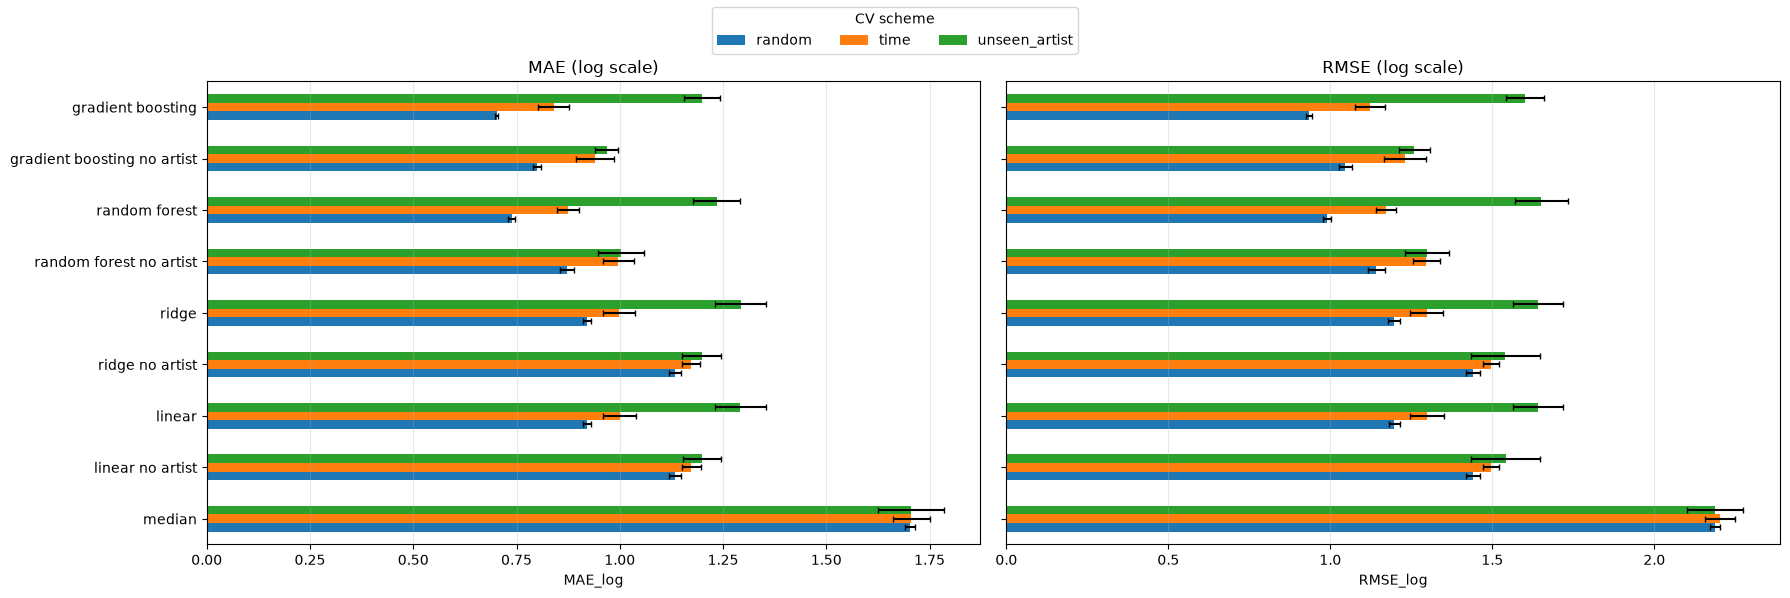

In [9]:
metrics = {
    "MAE_log":  "MAE (log scale)",
    "RMSE_log": "RMSE (log scale)",
}
order = list(models)

fig, axes = plt.subplots(1, len(metrics), figsize=(18, 6), sharey=True)
for ax, (metric, title) in zip(axes, metrics.items()):
    mean = cv_res.pivot_table(index="model", columns="scheme", values=metric, aggfunc="mean").loc[order]
    std  = cv_res.pivot_table(index="model", columns="scheme", values=metric, aggfunc="std").loc[order]
    mean.plot.barh(xerr=std, ax=ax, legend=False, capsize=2)
    ax.set_title(title)
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="CV scheme", loc="upper center", ncol=len(labels))
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()